In [1]:
# Assembled figure 4.5: 3D profiling sanity checks.
# Three sections, each a row of patchwork panels:
#   1. Cell, organoid, and cell/organoid counts (1.EDA/figures/cell_counts)
#   2. Volume and surface area calculations        (1.EDA/figures/volume_area)
#   3. Differential modeling of distinct features for MEKi treatments
#      (5.differential_analysis/figures/mek_*)
#   4. Linear-modeling variate importance: UpSet of features significant for
#      the biological variates (4.linear_modeling / interactive_dashboard)
# All panels are rebuilt from the source parquets with ggplot2 and composed
# with patchwork, reusing the shared manuscript theme and palettes.

packages <- c("ggplot2", "patchwork", "dplyr", "arrow", "RColorBrewer", "ggupset")
for (pkg in packages) {
    suppressPackageStartupMessages(
        suppressWarnings(
            library(pkg, character.only = TRUE)
        )
    )
}

find_git_root <- function() {
    cwd <- getwd()
    if (dir.exists(file.path(cwd, ".git"))) {
        return(cwd)
    }
    current_path <- cwd
    while (dirname(current_path) != current_path) {
        parent_path <- dirname(current_path)
        if (dir.exists(file.path(parent_path, ".git"))) {
            return(parent_path)
        }
        current_path <- parent_path
    }
    stop("No Git root directory found.")
}

root_dir <- find_git_root()
source(file.path(root_dir, "utils", "r_plot_themes.r"))
source(file.path(root_dir, "utils", "r_plot_funcs.r"))

# --- paths (all relative to the git root) --------------------------------
cell_counts_path <- file.path(root_dir, "1.EDA", "results", "cell_counts", "cell_counts.parquet")
organoid_cell_counts_path <- file.path(root_dir, "1.EDA", "results", "cell_counts", "organoid_cell_counts.parquet")
profiles_3d_dir <- file.path(root_dir, "data", "profiles_3D")
mek_tests_path <- file.path(
    root_dir, "interactive_dashboard", "data", "differential_analysis", "mek_contrast_level_tests.parquet"
)
lm_variate_upset_path <- file.path(
    root_dir, "interactive_dashboard", "data", "linear_modeling", "variate_importance",
    "variate_hit_upset_counts_all_scopes.parquet"
)

output_dir <- file.path(root_dir, "figures", "assembled_figure_4.5", "figures")
if (!dir.exists(output_dir)) {
    dir.create(output_dir, recursive = TRUE)
}
assembled_figure_path <- file.path(output_dir, "assembled_figure.pdf")

# NF0037_T1_CQ1 is a re-imaged QC replicate, excluded from every panel below.
excluded_patient <- "NF0037_T1_CQ1"
base_size <- 12

In [2]:
# ======================================================================
# Section 1: cell, organoid, and cell/organoid counts
# ======================================================================
cell_counts_df <- arrow::read_parquet(cell_counts_path) %>%
    filter(Metadata_Biology_PatientTumor != excluded_patient)
cell_counts_df$Metadata_Biology_TumorType <- factor(
    tumor_type_lookup[cell_counts_df$Metadata_Biology_PatientTumor],
    levels = names(tumor_type_palette)
)

# The handcrafted 3D (ZEDProfiler) single-cell and organoid count profiles.
sc_counts_df <- cell_counts_df %>% filter(Metadata_profile_name == "sc_norm_norm_profile_3D")
organoid_counts_df <- cell_counts_df %>% filter(Metadata_profile_name == "organoid_norm_norm_profile_3D")

organoid_cell_counts_df <- arrow::read_parquet(organoid_cell_counts_path) %>%
    filter(Metadata_Biology_PatientTumor != excluded_patient)
organoid_cell_counts_df$Metadata_Biology_TumorType <- factor(
    tumor_type_lookup[organoid_cell_counts_df$Metadata_Biology_PatientTumor],
    levels = names(tumor_type_palette)
)

# One count box per tumor type, colored by tumor type (the x axis already
# names the group, so the legend is dropped).
count_boxplot <- function(df, y_col, y_lab, title) {
    (
        plot_boxplot(
            df,
            x_col = "Metadata_Biology_TumorType",
            y_col = y_col,
            fill_col = "Metadata_Biology_TumorType",
            x_lab = "Tumor type",
            y_lab = y_lab,
            custom_palette = tumor_type_palette,
            x_text = "default",
            show_legend = FALSE,
            base_size = base_size
        )
        + labs(title = title)
    )
}

panel_sc_counts <- count_boxplot(
    sc_counts_df, "Metadata_n_cells_norm_by_well_fov",
    "Cells per well FOV", "Single-cell counts"
)
panel_organoid_counts <- count_boxplot(
    organoid_counts_df, "Metadata_n_cells_norm_by_well_fov",
    "Organoids per well FOV", "Organoid counts"
)
panel_cells_per_organoid <- count_boxplot(
    organoid_cell_counts_df, "mean_cells_per_organoid",
    "Mean cells per organoid", "Cells per organoid"
)

In [3]:
# ======================================================================
# Section 2: volume and surface area calculations
# (3D organoid and single-cell profiles)
# ======================================================================
patients_3d <- setdiff(
    list.dirs(profiles_3d_dir, recursive = FALSE, full.names = FALSE),
    c("all_patients", excluded_patient)
)

# Read one 3D shape measurement (volume + surface area) across every patient,
# tagging each row with its tumor type from the patient directory via
# tumor_type_lookup (rather than the per-row tumor-type column, a few of whose
# QC rows carry a missing value), matching how the count panels assign tumor
# type above.
load_3d_shape <- function(qc_file, volume_col, surface_area_col) {
    df <- bind_rows(lapply(patients_3d, function(patient) {
        f <- file.path(profiles_3d_dir, patient, "4.qc_profiles", qc_file)
        if (!file.exists(f)) {
            return(NULL)
        }
        d <- arrow::read_parquet(f, col_select = c(volume_col, surface_area_col))
        d$Metadata_Biology_TumorType <- tumor_type_lookup[[patient]]
        d
    }))
    df$Metadata_Biology_TumorType <- factor(
        df$Metadata_Biology_TumorType, levels = names(tumor_type_palette)
    )
    df
}

organoid_shape_df <- load_3d_shape(
    "organoid_flagged_outliers.parquet",
    "Organoid_NoChannel_VolumeSizeShape_Volume",
    "Organoid_NoChannel_VolumeSizeShape_SurfaceArea"
)
sc_shape_df <- load_3d_shape(
    "sc_flagged_outliers.parquet",
    "Cell_NoChannel_VolumeSizeShape_Volume",
    "Cell_NoChannel_VolumeSizeShape_SurfaceArea"
)

# Violin + boxplot of a per-object 3D shape measurement, by tumor type, on a
# log10 axis (volume and surface area both span orders of magnitude).
shape_violin_box <- function(df, y_col, y_lab, title) {
    (
        ggplot(df, aes(x = Metadata_Biology_TumorType, y = .data[[y_col]], fill = Metadata_Biology_TumorType))
        + geom_violin(alpha = 0.6, trim = TRUE)
        + geom_boxplot(width = 0.15, alpha = 0.85, outlier.size = 0.2, outlier.alpha = 0.2)
        + scale_fill_manual(values = tumor_type_palette)
        + scale_y_log10()
        + labs(title = title, x = "Tumor type", y = y_lab)
        + theme_manuscript(base_size = base_size, x_text = "angled")
        + theme(legend.position = "none")
    )
}

panel_organoid_volume <- shape_violin_box(
    organoid_shape_df, "Organoid_NoChannel_VolumeSizeShape_Volume",
    expression("Volume (voxels, log"[10] * ")"), "Organoid volume"
)
panel_organoid_surface_area <- shape_violin_box(
    organoid_shape_df, "Organoid_NoChannel_VolumeSizeShape_SurfaceArea",
    expression("Surface area (log"[10] * ")"), "Organoid surface area"
)
panel_sc_volume <- shape_violin_box(
    sc_shape_df, "Cell_NoChannel_VolumeSizeShape_Volume",
    expression("Volume (voxels, log"[10] * ")"), "Single-cell volume"
)
panel_sc_surface_area <- shape_violin_box(
    sc_shape_df, "Cell_NoChannel_VolumeSizeShape_SurfaceArea",
    expression("Surface area (log"[10] * ")"), "Single-cell surface area"
)

Warning message:
“Using an external vector in selections was deprecated in tidyselect 1.1.0.
ℹ Please use `all_of()` or `any_of()` instead.
  # Was:
  data %>% select(volume_col)

  # Now:
  data %>% select(all_of(volume_col))

See <https://tidyselect.r-lib.org/reference/faq-external-vector.html>.”
Warning message:
“Using an external vector in selections was deprecated in tidyselect 1.1.0.
ℹ Please use `all_of()` or `any_of()` instead.
  # Was:
  data %>% select(surface_area_col)

  # Now:
  data %>% select(all_of(surface_area_col))

See <https://tidyselect.r-lib.org/reference/faq-external-vector.html>.”


In [4]:
# ======================================================================
# Section 3: differential modeling of distinct features for MEKi treatments
# ======================================================================
Q_THRESHOLD <- 0.05
compartment_labels <- c(organoid = "Organoid", single_cell = "Single cell")
contrast_levels <- c("MEKi vs DMSO", "MEKi vs Staurosporine", "MEKi vs Digoxin")
level_labels <- c(
    within_patient = "Within patient",
    across_patients = "Across patients",
    within_tumor_type = "Within tumor type",
    across_tumor_types_shared = "Across tumor types (shared)",
    across_tumor_types_differ = "Across tumor types (differ)"
)

mek_tests_df <- arrow::read_parquet(mek_tests_path) %>%
    mutate(
        significant = !is.na(q) & q < Q_THRESHOLD,
        compartment = factor(compartment_labels[compartment], levels = compartment_labels),
        contrast = factor(contrast, levels = contrast_levels),
        level = factor(level_labels[level], levels = level_labels),
        # a handful of features carry no category; group them as "Other"
        feature_category = dplyr::coalesce(feature_category, "Other")
    )

# --- F1: how many significant features (overview) ------------------------
# One standalone heatmap per compartment (rather than one facet_wrap figure):
# faceting dropped the single-cell panel's y-axis labels so the two heatmaps
# shared the organoid left axis, which read awkwardly. Both panels share the
# same fill limits so their colours stay comparable across compartments.
mek_count_df <- mek_tests_df %>%
    group_by(compartment, level, contrast) %>%
    summarise(n_significant = sum(significant), .groups = "drop")

mek_count_limits <- c(0, max(mek_count_df$n_significant))

# white tile labels where the (sqrt-scaled) purple fill is dark enough that
# black text is hard to read, black elsewhere
mek_count_df$label_color <- ifelse(
    sqrt(mek_count_df$n_significant) > 0.55 * sqrt(mek_count_limits[2]),
    "white", "black"
)

mek_count_heatmap <- function(compartment_name, show_legend = TRUE) {
    (
        ggplot(
            filter(mek_count_df, compartment == compartment_name),
            aes(x = contrast, y = level, fill = n_significant)
        )
        + geom_tile(color = "white", linewidth = 0.5)
        + geom_text(aes(label = n_significant, color = label_color), size = 3.5)
        + scale_fill_gradient(
            low = "white", high = "#54278f", trans = "sqrt",
            limits = mek_count_limits,
            guide = if (show_legend) guide_colourbar(barheight = unit(1.2, "in")) else "none"
        )
        + scale_color_identity()
        + scale_y_discrete(limits = rev)
        + labs(
            title = paste0(compartment_name, ":\nMEKi significant features (q < ", Q_THRESHOLD, ")"),
            x = NULL, y = NULL, fill = "Significant\nfeatures"
        )
        + theme_manuscript(base_size = base_size, x_text = "angled")
        + theme(panel.grid = element_blank())
    )
}

# both heatmaps share the same fill scale, so only one needs a colourbar
panel_mek_counts_organoid <- mek_count_heatmap("Organoid", show_legend = FALSE)
panel_mek_counts_sc <- mek_count_heatmap("Single cell", show_legend = TRUE)

# --- F2: which features -- UpSet of distinct significant features across
# the three MEKi contrasts (a feature is "in" a contrast's set if it is
# significant in any test for that contrast), one plot per compartment.
mek_feature_sets <- mek_tests_df %>%
    filter(significant) %>%
    group_by(compartment, feature) %>%
    summarise(contrasts = list(sort(unique(as.character(contrast)))), .groups = "drop")

mek_upset_plot <- function(compartment_name) {
    plot_df <- mek_feature_sets %>% filter(compartment == compartment_name)
    (
        ggplot(plot_df, aes(x = contrasts))
        + geom_bar(fill = "#54278f")
        + geom_text(stat = "count", aes(label = after_stat(count)), vjust = -0.4, size = 3)
        + scale_x_upset(sets = contrast_levels)
        + scale_y_continuous(expand = expansion(mult = c(0.02, 0.15)))
        + labs(
            title = paste0(compartment_name, ":\nshared features"),
            x = NULL, y = "Distinct features"
        )
        + theme_manuscript(base_size = base_size)
        + theme_combmatrix(combmatrix.label.text = element_text(size = base_size))
    )
}

panel_mek_upset_organoid <- mek_upset_plot("Organoid")
panel_mek_upset_sc <- mek_upset_plot("Single cell")

# --- F3: what types of features -- distinct significant features by
# feature category, per compartment.
mek_category_df <- mek_tests_df %>%
    filter(significant) %>%
    distinct(compartment, feature, feature_category)
# order categories by total frequency, "Other" always last
category_order <- mek_category_df %>%
    filter(feature_category != "Other") %>%
    count(feature_category, sort = TRUE) %>%
    pull(feature_category)
category_order <- c(category_order, "Other")
mek_category_df$feature_category <- factor(mek_category_df$feature_category, levels = rev(category_order))
mek_category_palette <- setNames(
    colorRampPalette(brewer.pal(8, "Dark2"))(length(category_order)), category_order
)

# One standalone bar panel per compartment (rather than one facet_wrap figure)
# so each keeps its own category (y) axis.
mek_category_barplot <- function(compartment_name) {
    (
        ggplot(
            filter(mek_category_df, compartment == compartment_name),
            aes(y = feature_category, fill = feature_category)
        )
        + geom_bar()
        + geom_text(stat = "count", aes(label = after_stat(count)), hjust = -0.2, size = 3)
        + scale_fill_manual(values = mek_category_palette)
        + scale_x_continuous(expand = expansion(mult = c(0.02, 0.18)))
        + labs(
            title = paste0(compartment_name, ": MEKi feature categories"),
            x = "Distinct features", y = NULL
        )
        + theme_manuscript(base_size = base_size)
        + theme(legend.position = "none")
    )
}

panel_mek_category_organoid <- mek_category_barplot("Organoid")
panel_mek_category_sc <- mek_category_barplot("Single cell")

In [5]:
# ======================================================================
# Section 4: linear modeling variate importance (biological variates)
# UpSet of how many features are statistically significant for treatment and
# the biological covariates (cell count, organoid count, cells per organoid),
# pooled across every linear model (model_set "original", scope "all_models").
# ======================================================================
bio_variate_labels <- c(
    treatment = "Treatment",
    cell_count = "Cell count",
    organoid_count = "Organoid count",
    cell_per_organoid_count = "Cells per organoid"
)
bio_variate_order <- unname(bio_variate_labels)

lm_bio_upset_df <- arrow::read_parquet(lm_variate_upset_path) %>%
    filter(model_set == "original", scope == "all_models") %>%
    mutate(sets = lapply(
        strsplit(combination, " \\+ "),
        function(terms) unname(bio_variate_labels[trimws(terms)])
    ))

panel_lm_bio_upset <- (
    ggplot(lm_bio_upset_df, aes(x = sets, y = n_features))
    + geom_col(fill = "#1b9e77")
    + geom_text(aes(label = n_features), vjust = -0.4, size = 3)
    + scale_x_upset(sets = bio_variate_order)
    + scale_y_continuous(expand = expansion(mult = c(0.02, 0.15)))
    + labs(
        title = "Linear modeling: biological variates",
        x = NULL, y = "Significant features"
    )
    + theme_manuscript(base_size = base_size)
    + theme_combmatrix(combmatrix.label.text = element_text(size = base_size))
)

Warning message:
“Removed 129 rows containing non-finite outside the scale range
(`stat_boxplot()`).”
Warning message:
“Removed 1 row containing non-finite outside the scale range
(`stat_ydensity()`).”
Warning message:
“Removed 1 row containing non-finite outside the scale range (`stat_boxplot()`).”
Warning message:
“Removed 1 row containing non-finite outside the scale range
(`stat_ydensity()`).”
Warning message:
“Removed 1 row containing non-finite outside the scale range (`stat_boxplot()`).”
Warning message:
“Removed 91 rows containing non-finite outside the scale range
(`stat_ydensity()`).”
Warning message:
“Removed 91 rows containing non-finite outside the scale range
(`stat_boxplot()`).”
Warning message:
“Removed 128 rows containing non-finite outside the scale range
(`stat_ydensity()`).”
Warning message:
“Removed 128 rows containing non-finite outside the scale range
(`stat_boxplot()`).”
Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please

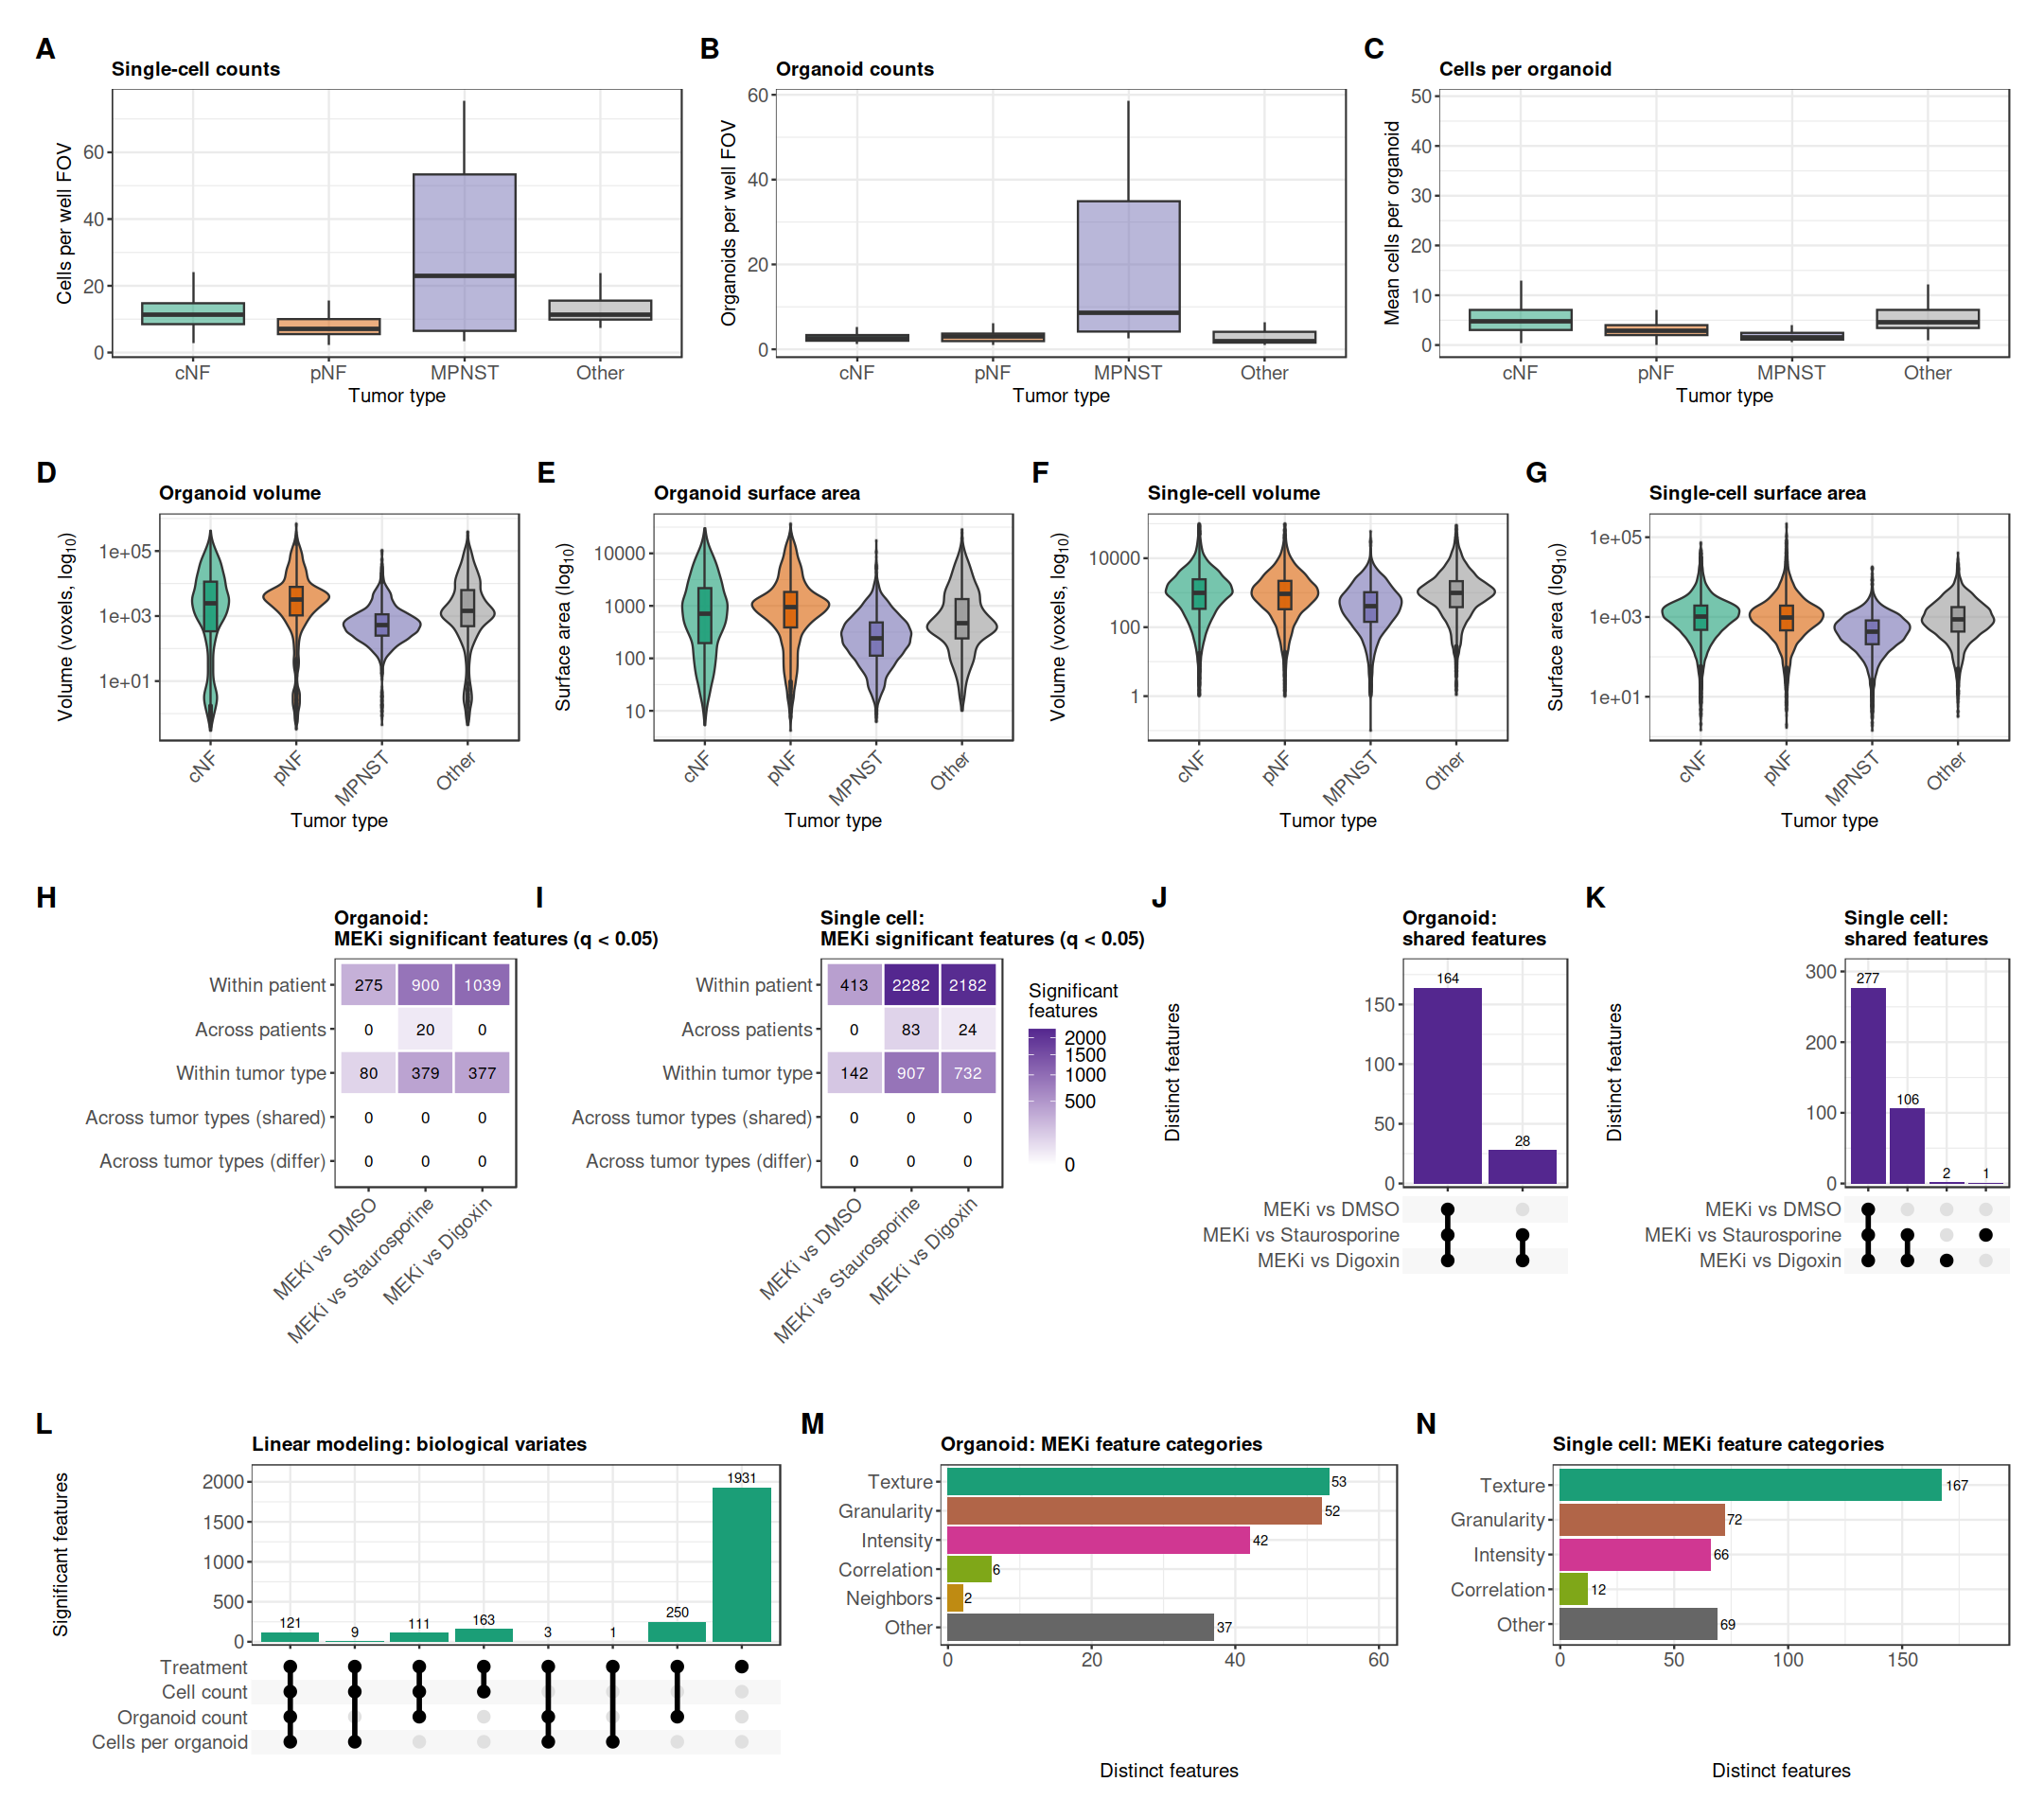

In [6]:
# ======================================================================
# Assemble with patchwork
# ======================================================================
width <- 18
height <- 16
options(repr.plot.width = width, repr.plot.height = height)

# Each row is composed on its own and then wrapped with wrap_elements() before
# stacking. Patchwork otherwise aligns every panel's inner plotting area to one
# global column grid (so the widest y-axis label in the whole figure -- here
# "Across tumor types (shared)" -- pushes the panel start in every row and
# leaves a large gap on the left of rows with short labels). wrap_elements()
# makes each row an opaque block, so panels are only aligned within their row
# and each row fills the width evenly. Panel tags are therefore set per panel
# (the auto tagger would see one element per wrapped row).
#   row 1 (A-C) = 3 count panels
#   row 2 (D-G) = 4 volume / surface-area panels
#   row 3 (H-K) = MEKi significant-feature heatmaps (per compartment) + MEKi
#                 UpSets (per compartment)
#   row 4 (L-N) = linear-modeling biological-variate UpSet + MEKi feature-
#                 category breakdown (per compartment)
tag_theme <- theme(plot.tag = element_text(face = "bold", size = 18))

row_counts <- (
    wrap_plots(
        panel_sc_counts + labs(tag = "A"),
        panel_organoid_counts + labs(tag = "B"),
        panel_cells_per_organoid + labs(tag = "C"),
        nrow = 1
    )
    & tag_theme
)
row_shape <- (
    wrap_plots(
        panel_organoid_volume + labs(tag = "D"),
        panel_organoid_surface_area + labs(tag = "E"),
        panel_sc_volume + labs(tag = "F"),
        panel_sc_surface_area + labs(tag = "G"),
        nrow = 1
    )
    & tag_theme
)
row_mek <- (
    wrap_plots(
        panel_mek_counts_organoid + labs(tag = "H"),
        panel_mek_counts_sc + labs(tag = "I"),
        panel_mek_upset_organoid + labs(tag = "J"),
        panel_mek_upset_sc + labs(tag = "K"),
        nrow = 1, widths = c(1.05, 1.05, 0.95, 0.95)
    )
    & tag_theme
)
row_lm_categories <- (
    wrap_plots(
        panel_lm_bio_upset + labs(tag = "L"),
        panel_mek_category_organoid + labs(tag = "M"),
        panel_mek_category_sc + labs(tag = "N"),
        nrow = 1, widths = c(1.1, 0.95, 0.95)
    )
    & tag_theme
)

final_plot <- wrap_plots(
    wrap_elements(row_counts),
    wrap_elements(row_shape),
    wrap_elements(row_mek),
    wrap_elements(row_lm_categories),
    ncol = 1,
    heights = c(1, 1, 1.25, 1)
)

ggsave(assembled_figure_path, plot = final_plot, width = width, height = height, dpi = 600)
final_plot